# Dataset preprocessing and training handover

## Summary
This notebook applies the recorded exclusion policy, prepares class targets and task manifests, and verifies real model-input batches. It uses the EDA notebook's source records; it does not run neural-model training.

## Context and methods
Exact duplicates retain test before validation before training. Conflicting repeated targets and incompatible joint mask/caption flags are quarantined, not relabelled. Exact frame/tile collisions protect partitions across datasets. Original imagery stays immutable. All geometric changes are recorded.

In [1]:
from pathlib import Path
import os, sys, json, importlib.util, subprocess
try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    IN_COLAB = False
roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in roots if (p / 'configs/datasets.yaml').exists()), None)
if PROJECT_ROOT is None and IN_COLAB:
    PROJECT_ROOT = Path('/content/TerraWatch')
    if not (PROJECT_ROOT / '.git').exists():
        subprocess.run(['git','clone','--branch','data-pipeline',
            'https://github.com/shoaib2000857/Group-7-DS-and-AI-Lab-Project.git',str(PROJECT_ROOT)],check=True)
    subprocess.run([sys.executable,'-m','pip','install','-q','-r',str(PROJECT_ROOT/'requirements-data.txt')],check=True)
if PROJECT_ROOT is None:
    raise RuntimeError('Clone the project first, then open this notebook in its notebooks folder. See notebooks/README.md.')
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path: sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.data.catalog import load_catalog
from src.data.preprocess import read_jsonl
AUDIT_DIR = PROJECT_ROOT / 'outputs/data'
PROCESSED_DIR = PROJECT_ROOT / 'data/processed'
DATA_ROOT = os.getenv('TERRAWATCH_DATA_ROOT')  # e.g. /content/drive/MyDrive/TerraWatch_Extracted
CONFIG = PROJECT_ROOT / 'configs/datasets.yaml'


In [2]:
# Optional: run only when the datasets are in Google Drive and you are in Colab.
MOUNT_DRIVE = IN_COLAB
if MOUNT_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_ROOT = '/content/drive/MyDrive/TerraWatch_Extracted'


## Data
Run the EDA notebook first. This notebook deliberately fails rather than making up a missing source audit.

In [3]:
assert (AUDIT_DIR/'source_records.jsonl').exists(), 'Run 01_EDA first'
source_rows=read_jsonl(AUDIT_DIR/'source_records.jsonl')
display(pd.DataFrame(source_rows).groupby(['dataset','official_split']).size().rename('source_pairs').to_frame())

source_pairs
dataset       official_split              
levir_cd_plus train                      8
levir_mci     test                    1929
              train                   6815
              val                     1333
s2looking     train                      5
second_cc     test                    1227
              train                   4219
              val                      595
sysu_cd       train                      8

## Results
### Prepare targets and partitions
RGB is resized bilinearly and categorical targets with nearest neighbour. Captions stay attached to full frames; no crop or rotation silently changes their location words. Source images remain available at native resolution for VLM processors.

In [4]:
from src.data.preprocess import prepare
RERUN_PREPARATION = not (AUDIT_DIR/'preparation_summary.json').exists()
IMAGE_SIZE = 256  # set None to retain native sizes; batching then requires a task-specific shape policy
if RERUN_PREPARATION:
    prepare(AUDIT_DIR, PROCESSED_DIR, CONFIG, IMAGE_SIZE)
prepared=json.loads((AUDIT_DIR/'preparation_summary.json').read_text())
display(pd.Series({k:prepared[k] for k in ['source_records','prepared_records','excluded_records','duplicate_groups','whole_changed_masks_lost_after_resize']}).to_frame('value'))
display(pd.Series(prepared['by_dataset_split'],name='prepared_pairs').to_frame())

,value
source_records,16139
prepared_records,14470
excluded_records,1669
duplicate_groups,865
whole_changed_masks_lost_after_resize,0


,prepared_pairs
levir_mci/test,1858
levir_mci/train,6444
levir_mci/val,1242
s2looking/train,5
sysu_cd/train,8
second_cc/test,1142
second_cc/train,3241
second_cc/val,530


### Inspect exclusions without rewriting ground truth

In [5]:
exclusions=json.loads((PROCESSED_DIR/'exclusions.json').read_text())
display(pd.Series(prepared['exclusion_reasons_nonexclusive'],name='reason_count').to_frame())
display(pd.DataFrame([{'pair_id':k,'reasons':', '.join(v)} for k,v in list(exclusions.items())[:10]]))

,reason_count
mask_caption_changeflag_conflict,797
exact_frame_or_tile_cross_split,404
exact_repeated_pair,868
inconsistent_duplicate_targets,12
perceptual_cross_split_candidate,2


,pair_id,reasons
0,levir_mci/test/test_000031,mask_caption_changeflag_conflict
1,levir_mci/test/test_000202,mask_caption_changeflag_conflict
2,levir_mci/test/test_000248,mask_caption_changeflag_conflict
3,levir_mci/test/test_000260,mask_caption_changeflag_conflict
4,levir_mci/test/test_000264,mask_caption_changeflag_conflict
5,levir_mci/test/test_000268,mask_caption_changeflag_conflict
6,levir_mci/test/test_000274,mask_caption_changeflag_conflict
7,levir_mci/test/test_000278,mask_caption_changeflag_conflict
8,levir_mci/test/test_000281,mask_caption_changeflag_conflict
9,levir_mci/test/test_000296,mask_caption_changeflag_conflict


### Task-dependent training data
Separate datasets support separate objectives. Binary building labels do not teach road negatives; broad SYSU change does not equal building-only change. The curriculum is described in docs/data/Training_Data_Plan.md.

In [6]:
display(pd.DataFrame(prepared['tasks']).T.fillna(0).astype(int))

,test,train,val
building_detection,1858,6449,1242
road_detection,1858,6444,1242
general_change_pretraining,0,8,0
semantic_change,1142,3241,530
captioning,3000,9685,1772
instruction_tuning,14686,83188,0


### Verify every retained sample
Set a limit only for a clearly labelled smoke check. The saved validation output records whether all records or a bounded subset were visited.

In [7]:
from src.data.cli import verify
RERUN_VERIFICATION = not (AUDIT_DIR/'loader_validation.json').exists()
if RERUN_VERIFICATION: verify(PROCESSED_DIR, AUDIT_DIR, limit=None)
validation=json.loads((AUDIT_DIR/'loader_validation.json').read_text())
display(pd.DataFrame(validation['splits']).T)

,records,records_verified,scope
train,9698,9698,all retained records
val,1772,1772,all retained records
test,3000,3000,all retained records


### Inspect a real batch and reference separation

Images: (4, 2, 3, 256, 256) float32 range 0.0 1.0
Targets: (4, 256, 256) classes [0]


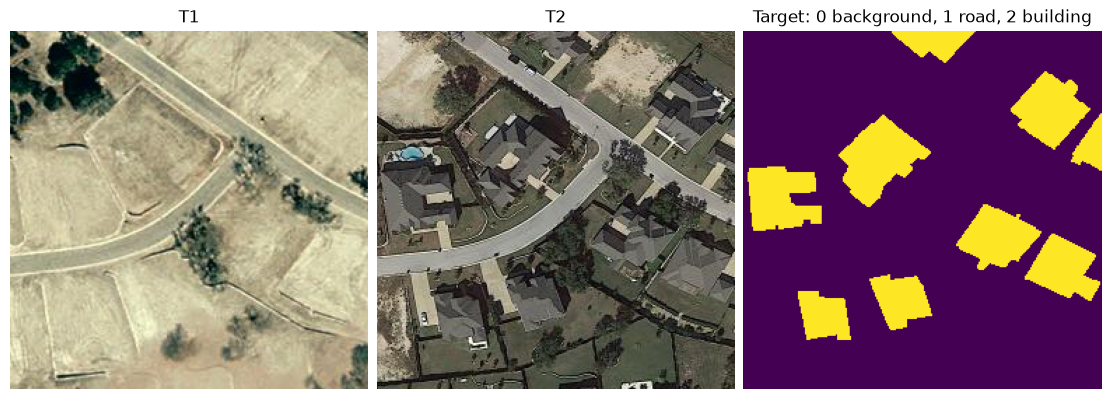

Reference count: 5


Inference fields: ['pair_id', 't1', 't2']


In [8]:
from src.data.dataset import PairDataset
ds=PairDataset(PROCESSED_DIR/'train.jsonl',PROCESSED_DIR,include_references=True)
batch=ds.batch(range(min(4,len(ds))))
print('Images:',batch['images'].shape,batch['images'].dtype,'range',float(batch['images'].min()),float(batch['images'].max()))
print('Targets:',batch['targets'].shape,'classes',np.unique(batch['targets']))
profile_map={r['pair_id']:r for r in read_jsonl(AUDIT_DIR/'profiles.jsonl')}
example=next(i for i,r in enumerate(ds.rows) if r['dataset']=='levir_mci' and profile_map[r['pair_id']].get('changed_fraction',0)>.1)
sample=ds[example]
fig,axes=plt.subplots(1,3,figsize=(11,4),layout='constrained')
for ax,key in zip(axes[:2],['t1','t2']): ax.imshow(sample[key]); ax.set_title(key.upper()); ax.axis('off')
axes[2].imshow(sample['targets']['target'],vmin=0,vmax=2,cmap='viridis'); axes[2].set_title('Target: 0 background, 1 road, 2 building'); axes[2].axis('off'); plt.show()
print('Reference count:',len(sample['references']))
infer=PairDataset(PROCESSED_DIR/'test_inference.jsonl',PROCESSED_DIR,include_targets=False)
assert set(infer[0])=={'pair_id','t1','t2'}
print('Inference fields:',sorted(infer[0]))
ds.close(); infer.close()

## Takeaways

In [9]:
display(Markdown(f"Prepared **{prepared['prepared_records']:,}** pairs with **{prepared['excluded_records']:,}** recorded exclusions across the available sources. Validation scope is shown above. Training-ready data is not a model-performance or human-factuality result."))

Prepared **14,470** pairs with **1,669** recorded exclusions across the available sources. Validation scope is shown above. Training-ready data is not a model-performance or human-factuality result.